In [1]:
!pip install pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df =pd.read_csv('/Users/foroghakbari/Zoomcamp/ml_course/zoomcamp_ml/regression/car_fuel_efficiency_2026.csv')

In [4]:
df.head(10)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
5,2007,USA,Hybrid,Front-wheel drive,2,2290,6,266.0,4260,18.8,31.2
6,1992,Asia,Gasoline,Front-wheel drive,2,2270,6,250.0,4310,21.7,26.8
7,2005,USA,Gasoline,Front-wheel drive,4,2370,6,279.0,4090,17.4,30.2
8,1997,Asia,Gasoline,Rear-wheel drive,3,2330,6,251.0,4230,19.5,30.9
9,2004,USA,Diesel,All-wheel drive,5,2330,6,280.0,4620,17.7,31.2


In [5]:
df=df.fillna(0)

Skewness: 0.081


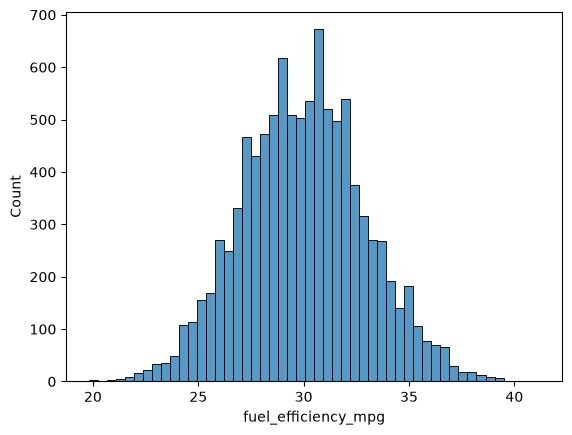

In [6]:
sns.histplot(df.fuel_efficiency_mpg, bins=50) #no long tail 
#check symmetry 
print(f"Skewness: {df['fuel_efficiency_mpg'].skew():.3f}")
 #looks relatively normally distributed

In [7]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,0.0,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,0.0,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [8]:
from sklearn.model_selection import train_test_split

In [25]:

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


In [26]:
Y_train = df_train.fuel_efficiency_mpg.values
Y_val = df_val.fuel_efficiency_mpg.values
Y_test = df_test.fuel_efficiency_mpg.values

In [27]:
df_train = df_train.drop(columns=['fuel_efficiency_mpg'])
df_val = df_val.drop(columns=['fuel_efficiency_mpg'])

In [28]:
from sklearn.feature_extraction import DictVectorizer

In [29]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

Question 1

Let's train a decision tree regressor to predict the `fuel_efficiency_mpg` variable. 

* Train a model with `max_depth=1`.


Which original feature is used for splitting the data? If you use
`DictVectorizer`, map a one-hot feature such as `origin=USA` back to its
original column name.


* `'vehicle_weight'`
* `'model_year'`
* `'origin'`
* `'fuel_type'`



In [13]:
from sklearn.tree import DecisionTreeClassifier

In [30]:
from sklearn.tree import DecisionTreeRegressor, export_text




In [14]:
X_train

array([[1.90e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 1.00e+00, 4.28e+03],
       [1.88e+01, 1.00e+00, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.58e+03],
       [2.06e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 4.15e+03],
       ...,
       [1.91e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 0.00e+00, 4.44e+03],
       [1.94e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 4.00e+03],
       [1.78e+01, 0.00e+00, 1.00e+00, ..., 1.00e+00, 0.00e+00, 4.27e+03]],
      shape=(6000, 17))

In [15]:
Y_train

array([30.8, 29.7, 27.6, ..., 30.7, 32.1, 29.6], shape=(6000,))

In [34]:
dt = DecisionTreeRegressor(max_depth=4, random_state=11) #depth of tree will not be infinite
dt.fit(X_train, Y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- fuel_type=Gasoline <= 0.50
|   |   |--- fuel_type=Diesel <= 0.50
|   |   |   |--- vehicle_weight <= 4265.00
|   |   |   |   |--- value: [33.06]
|   |   |   |--- vehicle_weight >  4265.00
|   |   |   |   |--- value: [31.03]
|   |   |--- fuel_type=Diesel >  0.50
|   |   |   |--- vehicle_weight <= 4105.00
|   |   |   |   |--- value: [31.29]
|   |   |   |--- vehicle_weight >  4105.00
|   |   |   |   |--- value: [29.06]
|   |--- fuel_type=Gasoline >  0.50
|   |   |--- vehicle_weight <= 4245.00
|   |   |   |--- origin=USA <= 0.50
|   |   |   |   |--- value: [29.50]
|   |   |   |--- origin=USA >  0.50
|   |   |   |   |--- value: [27.95]
|   |   |--- vehicle_weight >  4245.00
|   |   |   |--- origin=USA <= 0.50
|   |   |   |   |--- value: [27.57]
|   |   |   |--- origin=USA >  0.50
|   |   |   |   |--- value: [26.15]
|--- model_year >  1997.50
|   |--- fuel_type=Gasoline <= 0.50
|   |   |--- horsepower <= 256.50
|   |   |   |--- model_year <= 2012.50
|   |  

In [32]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



Question 2

Train a random forest regressor with these parameters:

* `n_estimators=10`
* `random_state=1`
* `n_jobs=-1` (optional - to make training faster)


What's the RMSE of this model on the validation data?

* 0.1837
* 1.837
* 18.37
* 183.7




In [42]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import roc_auc_score
from sklearn.metrics import mean_squared_error

In [51]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1) #n_jobs=-1 means use all cores
rf.fit(X_train, Y_train)
y_pred = rf.predict(X_val)
rmse = np.sqrt(mean_squared_error(Y_val, y_pred))
print(round(rmse, 3))


1.834


Question 3

Now let's experiment with the `n_estimators` parameter

* Try these values of this parameter: `[10, 50, 100, 150]`.
* Set `random_state` to `1`.
* Evaluate the model on the validation dataset.


Which value gives the lowest validation RMSE? Consider 3 decimal places for
calculating the answer.

- 10
- 50
- 100
- 150

In [ ]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1) #n_jobs=-1 means use all cores
rf.fit(X_train, Y_train)
y_pred = rf.predict(X_val)
rmse = np.sqrt(mean_squared_error(Y_val, y_pred))
print(round(rmse, 3))

In [55]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rmse_val = []
for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, Y_train)
    y_pred = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(Y_val, y_pred))
    rmse_val.append((n, round(rmse, 3)))

    print(f'n_estimators={n}, RMSE={rmse:.3f}')

n_estimators=10, RMSE=1.834
n_estimators=50, RMSE=1.770
n_estimators=100, RMSE=1.768
n_estimators=150, RMSE=1.768


Question 4

Let's select the best `max_depth`:

* Try different values of `max_depth`: `[10, 15, 20, 25]`
* For each of these values,
  * try different values of `n_estimators` from `[10, 50, 100, 150]`
  * calculate the mean RMSE 
* Fix the random seed: `random_state=1`


What's the best `max_depth`, using the mean RMSE?

* 10
* 15
* 20
* 25


In [59]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rmse_val = []
for max_depth in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1, max_depth=max_depth)
        rf.fit(X_train, Y_train)
        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(Y_val, y_pred))
        rmse_val.append((max_depth, n, round(rmse, 3)))
        print(f'max_depth={max_depth}, n_estimators={n}, RMSE={rmse:.3f}')

max_depth=10, n_estimators=10, RMSE=1.785
max_depth=10, n_estimators=50, RMSE=1.750
max_depth=10, n_estimators=100, RMSE=1.746
max_depth=10, n_estimators=150, RMSE=1.746
max_depth=15, n_estimators=10, RMSE=1.834
max_depth=15, n_estimators=50, RMSE=1.773
max_depth=15, n_estimators=100, RMSE=1.767
max_depth=15, n_estimators=150, RMSE=1.766
max_depth=20, n_estimators=10, RMSE=1.830
max_depth=20, n_estimators=50, RMSE=1.770
max_depth=20, n_estimators=100, RMSE=1.765
max_depth=20, n_estimators=150, RMSE=1.766
max_depth=25, n_estimators=10, RMSE=1.840
max_depth=25, n_estimators=50, RMSE=1.772
max_depth=25, n_estimators=100, RMSE=1.769
max_depth=25, n_estimators=150, RMSE=1.769


In [61]:
best = min(rmse_val, key=lambda x: x[2])
print(f'Best: max_depth={best[0]}, n_estimators={best[1]}, RMSE={best[2]:.3f}')

Best: max_depth=10, n_estimators=100, RMSE=1.746


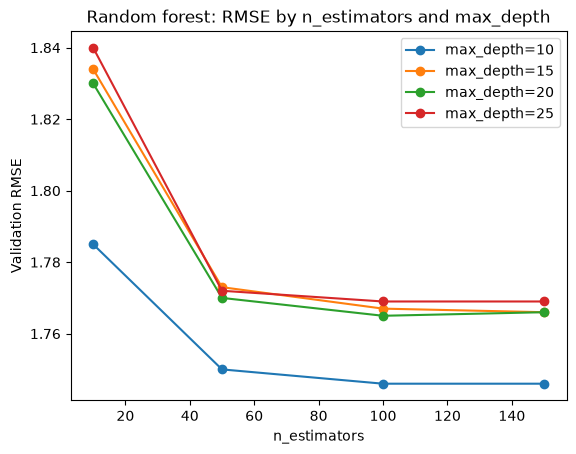

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

df_scores = pd.DataFrame(rmse_val, columns=['max_depth', 'n_estimators', 'rmse'])

for d in df_scores['max_depth'].unique():
    subset = df_scores[df_scores['max_depth'] == d]
    plt.plot(subset['n_estimators'], subset['rmse'], marker='o', label=f'max_depth={d}')

plt.xlabel('n_estimators')
plt.ylabel('Validation RMSE')
plt.title('Random forest: RMSE by n_estimators and max_depth')
plt.legend()
plt.show()

Question 5

We can extract feature importance information from tree-based models. 

At each step of the decision tree learning algorithm, it finds the best split. 
When doing it, we can calculate "gain" - the reduction in impurity before and after the split. 
This gain is quite useful in understanding what are the important features for tree-based models.

In Scikit-Learn, tree-based models contain this information in the
[`feature_importances_`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html#sklearn.ensemble.RandomForestRegressor.feature_importances_)
field. 

For this homework question, we'll find the most important feature:

* Train the model with these parameters:
  * `n_estimators=10`,
  * `max_depth=20`,
  * `random_state=1`,
  * `n_jobs=-1` (optional)
* Get the feature importance information from this model


What's the most important feature (among these 4)? 

* `vehicle_weight`
*	`horsepower`
* `acceleration`
* `engine_displacement

In [63]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, Y_train)

importances = pd.DataFrame({
    'feature': dv.get_feature_names_out(),
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(importances.head(10))

                         feature  importance
9                     model_year    0.295822
15                vehicle_weight    0.203649
6             fuel_type=Gasoline    0.160713
8                     horsepower    0.078254
4            engine_displacement    0.061008
0                   acceleration    0.055466
14                    origin=USA    0.042232
5               fuel_type=Diesel    0.021128
2   drivetrain=Front-wheel drive    0.020005
11                     num_doors    0.019724


Question 6

Now let's train an XGBoost model! For this question, we'll tune the `eta` parameter:

* Install XGBoost
* Create DMatrix for train and validation
* Create a watchlist
* Train a model with these parameters for 100 rounds:

``` python
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
```

Now change `eta` from `0.3` to `0.1`.

Which eta leads to the best RMSE score on the validation dataset?

* 0.3
* 0.1
* Both give equal value

## Learning in Public

In [64]:
import xgboost as xgb

In [66]:
features = dv.get_feature_names_out().tolist()
print(features)

['acceleration', 'drivetrain=All-wheel drive', 'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive', 'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline', 'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders', 'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA', 'vehicle_weight']


In [67]:
dtrain = xgb.DMatrix(X_train, label=Y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=Y_val, feature_names=features)

In [68]:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

In [69]:
model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=[(dval, 'val')], early_stopping_rounds=10)

[0]	val-rmse:2.46782
[1]	val-rmse:2.15784
[2]	val-rmse:1.97398
[3]	val-rmse:1.86662
[4]	val-rmse:1.80312
[5]	val-rmse:1.76216
[6]	val-rmse:1.74392
[7]	val-rmse:1.73976
[8]	val-rmse:1.73478
[9]	val-rmse:1.73282
[10]	val-rmse:1.73205
[11]	val-rmse:1.73227
[12]	val-rmse:1.73503
[13]	val-rmse:1.73466
[14]	val-rmse:1.73448
[15]	val-rmse:1.73512
[16]	val-rmse:1.73297
[17]	val-rmse:1.73517
[18]	val-rmse:1.73584
[19]	val-rmse:1.73664
[20]	val-rmse:1.73766


In [70]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
watchlist

[(<xgboost.core.DMatrix at 0x1266006e0>, 'train'),
 (<xgboost.core.DMatrix at 0x1266be350>, 'val')]

In [ ]:
scores = []

eta=0.3 final val RMSE: 1.826
eta=0.1 final val RMSE: 1.725


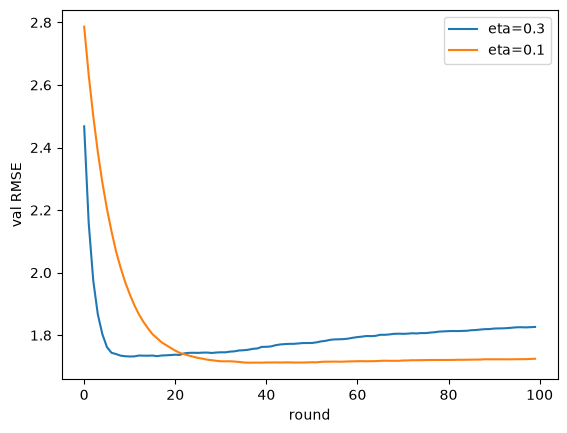

In [73]:
dtrain = xgb.DMatrix(X_train, label=Y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=Y_val, feature_names=features)
watchlist = [(dtrain, 'train'), (dval, 'val')]

def train_xgb(eta):
    params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }
    results = {}
    model = xgb.train(params, dtrain, num_boost_round=100,
                      evals=watchlist, evals_result=results, verbose_eval=False)
    return model, results

model_03, res_03 = train_xgb(0.3)
model_01, res_01 = train_xgb(0.1)

print('eta=0.3 final val RMSE:', round(res_03['val']['rmse'][-1], 3))
print('eta=0.1 final val RMSE:', round(res_01['val']['rmse'][-1], 3))

plt.plot(res_03['val']['rmse'], label='eta=0.3')
plt.plot(res_01['val']['rmse'], label='eta=0.1')
plt.xlabel('round')
plt.ylabel('val RMSE')
plt.legend()
plt.show()

In [ ]:
scores.keys()

In [ ]:

key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key